# Chapter 36: Relativity, One Learning Objective at a Time

This notebook walks through the chapter's eight learning objectives in
order. Each section states the idea, derives or checks the key formula
in SymPy, and works one numerical example.

| Objective | Topic | Key result |
|---|---|---|
| 36.1 | Reference frames, Galilean relativity | $x' = x - vt,\ u' = u - v$ |
| 36.2 | Principle of relativity | light moves at $c$ in every inertial frame |
| 36.3 | Events and measurements | an event is a point $(x, t)$; correct for light travel time |
| 36.4 | Simultaneity | $\Delta t' = -\gamma v\,\Delta x/c^2$ |
| 36.5 | Proper time, time dilation | $\Delta t = \gamma\,\Delta\tau$ |
| 36.6 | Lorentz transformations | $x' = \gamma(x - vt),\ t' = \gamma(t - vx/c^2)$ |
| 36.7 | Relativistic momentum | $p = \gamma m u$ |
| 36.8 | Energy, mass-energy equivalence | $E = \gamma mc^2,\ E^2 = (pc)^2 + (mc^2)^2$ |

Throughout, frame S′ moves at velocity $v$ along $+x$ relative to frame
S, $\beta = v/c$ and $\gamma = 1/\sqrt{1-\beta^2}$.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from sympy import symbols, sqrt, Rational, Matrix, simplify

c, v = symbols('c v', positive=True)
x, t = symbols('x t', real=True)
gamma = 1 / sqrt(1 - v**2 / c**2)

C = 299_792_458                            # m/s, exact by definition
gam = lambda b: 1 / np.sqrt(1 - b**2)      # numeric gamma from beta
print("sympy", sp.__version__)

sympy 1.14.0


# 36.1 — Reference frames and Galilean relativity

A **reference frame** is a coordinate system with clocks, used to
assign a position and a time to things that happen. An **inertial**
frame is one in which Newton's first law holds.

The everyday rule for switching between two inertial frames is the
**Galilean transformation**: $x' = x - vt$, $t' = t$. Differentiating
gives the velocity rule $u' = u - v$, and differentiating again shows
that acceleration is the same in both frames — so $F = ma$ looks the
same to both observers.

In [2]:
X = sp.Function('x')(t)                 # some object's position in S
Xp = X - v * t                          # Galilean: its position in S'

u_S, u_Sp = sp.diff(X, t), sp.diff(Xp, t)
print("velocity in S' :", u_Sp)
print("acceleration difference between frames:", sp.diff(Xp, t, 2) - sp.diff(X, t, 2))
assert sp.diff(Xp, t, 2) - sp.diff(X, t, 2) == 0

# the trouble: apply the same rule to a light pulse
print("\nGalilean prediction for light seen from S':  u' =", c - v)
v_earth = 29.8e3                        # m/s, Earth's orbital speed
print(f"for Earth's orbital motion that is a shift of {v_earth / C:.1e} of c")

velocity in S' : -v + Derivative(x(t), t)
acceleration difference between frames: 0

Galilean prediction for light seen from S':  u' = c - v
for Earth's orbital motion that is a shift of 9.9e-05 of c


Galilean relativity predicts that light should travel at $c - v$
relative to a moving observer. Experiments looking for that shift,
starting with Michelson and Morley, found none. Something in the
Galilean rules has to go.

# 36.2 — The principle of relativity

**All the laws of physics are the same in all inertial reference
frames.** Maxwell's equations are laws of physics and they predict
light waves travelling at $c$, so light travels at $c$ in *every*
inertial frame.

That single requirement fixes the replacement for the Galilean
transformation. Try the simplest change, a stretch factor $\gamma$:

$$x' = \gamma(x - vt), \qquad x = \gamma(x' + vt').$$

A light pulse leaving the origin must satisfy $x = ct$ in S and
$x' = ct'$ in S′. Demanding both pins down $\gamma$.

In [3]:
g, g2, T = symbols('gamma gamma2 T', positive=True)

Tp = g * (c * T - v * T) / c                       # from x' = g(x - v t) with x = cT, x' = cT'
condition = sp.expand(c * T - g * (c * Tp + v * Tp))     # from x = g(x' + v t'), must be zero
gamma_sq = sp.solve(condition.subs(g**2, g2), g2)[0]     # the condition is linear in gamma^2
print("gamma^2 =", gamma_sq)
assert simplify(gamma_sq - gamma**2) == 0
print("gamma   = 1/sqrt(1 - v^2/c^2)   (positive root, so that gamma -> 1 as v -> 0)")

gamma^2 = c**2/(c**2 - v**2)
gamma   = 1/sqrt(1 - v^2/c^2)   (positive root, so that gamma -> 1 as v -> 0)


So $\gamma = 1/\sqrt{1 - v^2/c^2}$: it is 1 at everyday speeds and
grows without bound as $v \to c$.

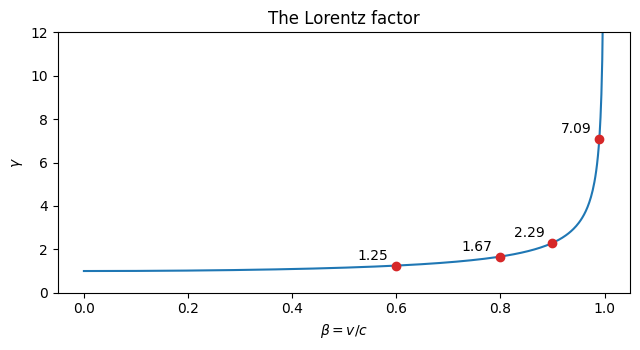

In [4]:
b = np.linspace(0, 0.999, 600)
plt.figure(figsize=(6.5, 3.6))
plt.plot(b, gam(b))
for bb in (0.6, 0.8, 0.9, 0.99):
    plt.plot(bb, gam(bb), 'o', color='C3')
    plt.annotate(f"{gam(bb):.2f}", (bb, gam(bb)), textcoords='offset points', xytext=(-28, 4))
plt.ylim(0, 12); plt.xlabel(r'$\beta = v/c$'); plt.ylabel(r'$\gamma$')
plt.title(r'The Lorentz factor'); plt.tight_layout(); plt.show()

# 36.3 — Events and measurements

An **event** is something that happens at one place and one instant:
a point $(x, y, z, t)$. Measuring an event's time means reading the
clock *located at the event*, not noting when you see it. If you are
somewhere else, you must subtract the time the light took to reach you.

**Example.** A firecracker explodes 600 m from you. You see the flash
when your clock reads 3.00 µs. When did the explosion happen?

In [5]:
d, t_seen = 600.0, 3.00e-6
t_event = t_seen - d / C
print(f"light travel time = {d / C * 1e6:.3f} us")
print(f"the explosion happened at t = {t_event * 1e6:.3f} us")
assert np.isclose(t_event * 1e6, 0.999, atol=1e-3)

light travel time = 2.001 us
the explosion happened at t = 0.999 us


Observers in the same frame, after making this correction, always
agree on when and where an event happened. Observers in *different*
frames do not — that is the subject of the next three sections.

# 36.4 — Simultaneity

Two events that are simultaneous in S ($\Delta t = 0$) but happen at
different places ($\Delta x \neq 0$) are **not** simultaneous in S′.
Using the time transformation that goes with $\gamma$ (derived in 36.6),
$t' = \gamma(t - vx/c^2)$:

In [6]:
def boost(xv, tv, vv=v):
    # event (x, t) in S  ->  (x', t') in S'
    gv = 1 / sqrt(1 - vv**2 / c**2)
    return gv * (xv - vv * tv), gv * (tv - vv * xv / c**2)

dx = symbols('Delta_x', real=True)
_, dtp = boost(dx, 0)
print("Delta t' =", dtp)

# two lightning strikes 600 m apart, simultaneous on the ground; train moves at 0.6c
num = float(dtp.subs({v: 0.6 * C, c: C, dx: 600}))
print(f"\ntrain at 0.6c: Delta t' = {num * 1e6:.3f} us  (the strike at the front happens first)")
assert np.isclose(num * 1e6, -1.501, atol=1e-3)

Delta t' = -Delta_x*v/(c**2*sqrt(1 - v**2/c**2))

train at 0.6c: Delta t' = -1.501 us  (the strike at the front happens first)


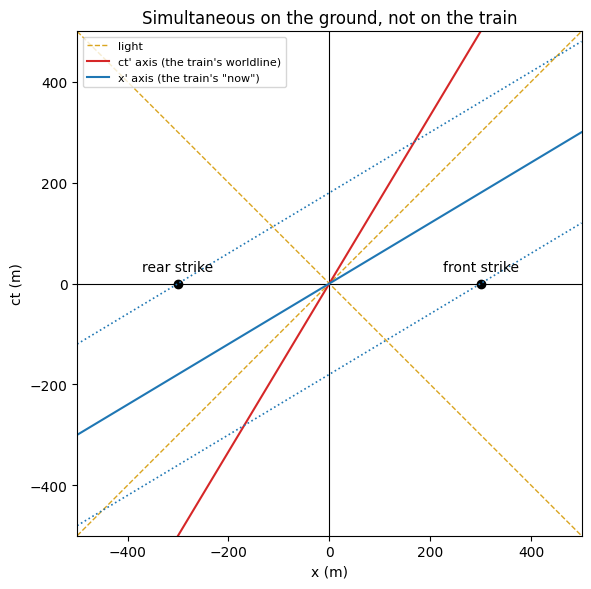

In [7]:
beta_demo = 0.6
s = np.array([-500, 500])
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(s, s, color='goldenrod', ls='--', lw=1, label='light')
ax.plot(s, -s, color='goldenrod', ls='--', lw=1)
ax.axhline(0, color='k', lw=0.8); ax.axvline(0, color='k', lw=0.8)
ax.plot(beta_demo * s, s, 'C3', label="ct' axis (the train's worldline)")
ax.plot(s, beta_demo * s, 'C0', label="x' axis (the train's \"now\")")
for xe in (-300, 300):
    ax.plot(xe, 0, 'ko')
    ax.plot(s, beta_demo * (s - xe), 'C0:', lw=1.2)
ax.text(-300, 25, 'rear strike', ha='center'); ax.text(300, 25, 'front strike', ha='center')
ax.set_xlim(-500, 500); ax.set_ylim(-500, 500); ax.set_aspect('equal')
ax.set_xlabel('x (m)'); ax.set_ylabel('ct (m)')
ax.set_title("Simultaneous on the ground, not on the train")
ax.legend(loc='upper left', fontsize=8); plt.tight_layout(); plt.show()

Read the diagram this way: the ground's lines of "same time" are
horizontal, and both strikes sit on one of them. The train's lines of
"same time" are tilted (dotted). The dotted line through the front
strike sits lower than the one through the rear strike, so on the train
the front strike is earlier.

# 36.5 — Proper time and time dilation

The **proper time** $\Delta\tau$ between two events is the time measured
in the frame where both events happen *at the same place* — one clock,
present at both events. Every other frame measures a longer interval:

$$\Delta t = \gamma\,\Delta\tau \;\ge\; \Delta\tau .$$

**Light-clock derivation.** A light pulse bounces between two mirrors a
height $h$ apart. In the clock's own frame one round trip takes
$\Delta\tau = 2h/c$. Seen from a frame where the clock moves at $v$, the
light travels along the hypotenuse of a triangle — still at speed $c$.

In [8]:
h, dt2 = symbols('h Delta_t2', positive=True)      # dt2 stands for (Delta t)^2

# half a tick, Pythagoras: hypotenuse c*dt/2, height h, base v*dt/2
tick_sq = sp.solve(sp.Eq(c**2 * dt2 / 4, h**2 + v**2 * dt2 / 4), dt2)[0]
dtau = 2 * h / c
ratio_sq = simplify(tick_sq / dtau**2)
print("(Delta t)^2 =", tick_sq)
print("(Delta t / Delta tau)^2 =", ratio_sq, " = gamma^2")
assert simplify(ratio_sq - gamma**2) == 0

(Delta t)^2 = 4*h**2/(c**2 - v**2)
(Delta t / Delta tau)^2 = c**2/(c**2 - v**2)  = gamma^2


**Example: muons.** A muon at rest lives $\tau = 2.20$ µs on
average. Muons made in the upper atmosphere move at about $0.995c$.
How far do they get, and what fraction survive a 10 km trip to the
ground?

In [9]:
tau, beta_mu, L = 2.20e-6, 0.995, 10e3
g_mu = gam(beta_mu)
print(f"gamma = {g_mu:.2f}")
print(f"mean lifetime in the lab frame = {g_mu * tau * 1e6:.1f} us  (proper lifetime {tau * 1e6:.2f} us)")
print(f"mean distance: {beta_mu * C * tau:.0f} m without time dilation, "
      f"{beta_mu * C * g_mu * tau / 1e3:.2f} km with it")

t_trip = L / (beta_mu * C)
with_td, without_td = np.exp(-t_trip / (g_mu * tau)), np.exp(-t_trip / tau)
print(f"fraction surviving 10 km: {with_td:.3f} with time dilation, {without_td:.1e} without")
print(f"in the muon's frame the 10 km of atmosphere is contracted to {L / g_mu:.0f} m")
assert np.isclose(g_mu, 10.01, atol=0.01) and np.isclose(with_td, 0.218, atol=0.002)

gamma = 10.01
mean lifetime in the lab frame = 22.0 us  (proper lifetime 2.20 us)
mean distance: 656 m without time dilation, 6.57 km with it
fraction surviving 10 km: 0.218 with time dilation, 2.4e-07 without
in the muon's frame the 10 km of atmosphere is contracted to 999 m


Both frames agree on the outcome (the muon reaches the ground) and
disagree on the reason: the ground says the muon's clock runs slow, the
muon says the atmosphere is short.

**Example: a round trip.** A traveller goes to a star 4.0 light-years
away and back at $0.8c$.

In [10]:
dist_ly, beta_trip = 4.0, 0.8
earth_years = 2 * dist_ly / beta_trip
ship_years = earth_years / gam(beta_trip)
print(f"Earth clocks: {earth_years:.1f} yr    traveller's clock (proper time): {ship_years:.1f} yr")
assert np.isclose(earth_years, 10) and np.isclose(ship_years, 6)

Earth clocks: 10.0 yr    traveller's clock (proper time): 6.0 yr


# 36.6 — The Lorentz transformations

$$x' = \gamma(x - vt), \qquad t' = \gamma\!\left(t - \frac{vx}{c^2}\right), \qquad y' = y,\quad z' = z .$$

Written on $(ct, x)$ it is a symmetric matrix. Three checks:
undoing a boost is a boost by $-v$; the **spacetime interval**
$(c\,\Delta t)^2 - (\Delta x)^2$ is the same in every frame; and
light still moves at $c$.

In [11]:
def Lmat(beta):
    gb = 1 / sqrt(1 - beta**2)
    return Matrix([[gb, -gb * beta], [-gb * beta, gb]])

B = symbols('beta', positive=True)
L = Lmat(B)
sp.pprint(L)

eta = sp.diag(1, -1)
assert (L * Lmat(-B)).applyfunc(simplify) == sp.eye(2)             # inverse is a boost by -v
assert (L.T * eta * L).applyfunc(simplify) == eta                  # interval is invariant
xp, tp = boost(c * t, t)                                           # a light pulse x = ct
assert simplify(xp / tp - c) == 0                                  # still moves at c in S'
print("\ninverse, invariant interval, and constant c all verified")

⎡     1           -β     ⎤
⎢───────────  ───────────⎥
⎢   ________     ________⎥
⎢  ╱      2     ╱      2 ⎥
⎢╲╱  1 - β    ╲╱  1 - β  ⎥
⎢                        ⎥
⎢    -β            1     ⎥
⎢───────────  ───────────⎥
⎢   ________     ________⎥
⎢  ╱      2     ╱      2 ⎥
⎣╲╱  1 - β    ╲╱  1 - β  ⎦

inverse, invariant interval, and constant c all verified


Everything earlier in the chapter is a special case. Apply the
transformation to the *difference* between two events:

In [12]:
Dx, Dt = symbols('Delta_x Delta_t', real=True)
Dxp, Dtp = boost(Dx, Dt)

# time dilation: both events at the same place in S
print("Delta x = 0   ->  Delta t' =", Dtp.subs(Dx, 0))

# simultaneity: both events at the same time in S
print("Delta t = 0   ->  Delta t' =", Dtp.subs(Dt, 0))

# length contraction: a rod at rest in S has proper length Delta x; S' must mark both ends
# at the same t', so choose Delta t to make Delta t' = 0
Dt_needed = sp.solve(Dtp, Dt)[0]
L_moving = simplify(Dxp.subs(Dt, Dt_needed))
print("Delta t' = 0  ->  Delta x' =", L_moving)
assert simplify(L_moving - Dx / gamma) == 0

Delta x = 0   ->  Delta t' = Delta_t/sqrt(1 - v**2/c**2)
Delta t = 0   ->  Delta t' = -Delta_x*v/(c**2*sqrt(1 - v**2/c**2))
Delta t' = 0  ->  Delta x' = Delta_x*sqrt(c**2 - v**2)/c


**Length contraction:** $L = L_0/\gamma$, where the proper length
$L_0$ is measured in the frame where the object is at rest.

**Velocity addition.** An object moves at $u$ in S. Its velocity in S′
is $u' = dx'/dt'$:

In [13]:
u = symbols('u', real=True)
xp, tp = boost(u * t, t)                    # object on the path x = u t
u_prime = simplify(xp / tp)
print("u' =", u_prime)
assert simplify(u_prime - (u - v) / (1 - u * v / c**2)) == 0
assert simplify(u_prime.subs(u, c) - c) == 0

# two boosts of 0.9c compose into one boost below c
w = (Rational(9, 10) + Rational(9, 10)) / (1 + Rational(81, 100))
assert (Lmat(Rational(9, 10)) * Lmat(Rational(9, 10)) - Lmat(w)).applyfunc(simplify) == sp.zeros(2)
print(f"0.9c 'plus' 0.9c = {w} c = {float(w):.4f} c   (Galilean answer: 1.8 c)")

u' = c**2*(u - v)/(c**2 - u*v)
0.9c 'plus' 0.9c = 180/181 c = 0.9945 c   (Galilean answer: 1.8 c)


# 36.7 — Relativistic momentum

With the new velocity rule, $p = mu$ is no longer conserved in every
frame. The quantity that is conserved is

$$p = \gamma_u\, m u, \qquad \gamma_u = \frac{1}{\sqrt{1 - u^2/c^2}} .$$

**Check with a collision.** In S, two identical lumps of mass $m$
approach at $\pm 0.6c$, collide and stick, ending at rest. Momentum is
conserved in S either way ($0 = 0$). Now view the same collision from
S′, moving at $0.8c$. Units: $c = 1$, $m = 1$.

In [14]:
add = lambda uu, vv: (uu - vv) / (1 - uu * vv)          # velocity in S' (c = 1)
G = lambda uu: 1 / sqrt(1 - uu**2)

uA, uB, vf = Rational(3, 5), -Rational(3, 5), Rational(4, 5)
uA_p, uB_p, lump_p = add(uA, vf), add(uB, vf), add(0, vf)
print("velocities in S':", uA_p, uB_p, "-> lump:", lump_p)

# classical momentum, lump of mass 2m
print("\nclassical    before:", uA_p + uB_p, "  after:", 2 * lump_p, "  -> NOT conserved")

# relativistic momentum; the lump's mass M is fixed by energy conservation in S
M = 2 * G(uA)
p_before = G(uA_p) * uA_p + G(uB_p) * uB_p
p_after = G(lump_p) * M * lump_p
print("relativistic before:", p_before, "  after:", p_after, "  -> conserved")
print("\nlump mass M =", M, "m   (more than 2m)")
assert uA_p + uB_p != 2 * lump_p and p_before == p_after == -Rational(10, 3)

velocities in S': -5/13 -35/37 -> lump: -4/5

classical    before: -640/481   after: -8/5   -> NOT conserved
relativistic before: -10/3   after: -10/3   -> conserved

lump mass M = 5/2 m   (more than 2m)


Two lessons in one example. Momentum is conserved in S′ only with
the factor $\gamma$. And it only works if the stuck-together lump has
mass $M = 2.5\,m$, not $2m$: the kinetic energy that disappeared in the
collision shows up as mass. That is 36.8.

At low speed the new formula reduces to the old one:

p = 3*m*u**5/(8*c**4) + m*u**3/(2*c**2) + m*u + O(u**6)


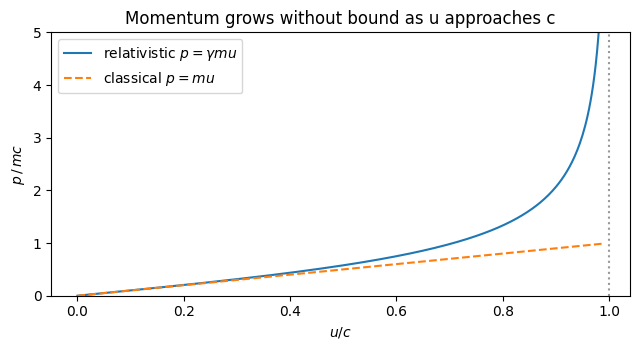

In [15]:
m = symbols('m', positive=True)
uu = symbols('u', positive=True)
p_rel = m * uu / sqrt(1 - uu**2 / c**2)
print("p =", sp.series(p_rel, uu, 0, 6))

b = np.linspace(0, 0.99, 400)
plt.figure(figsize=(6.5, 3.6))
plt.plot(b, gam(b) * b, label=r'relativistic $p = \gamma m u$')
plt.plot(b, b, '--', label=r'classical $p = m u$')
plt.axvline(1, color='0.6', ls=':')
plt.ylim(0, 5); plt.xlabel(r'$u/c$'); plt.ylabel(r'$p\,/\,mc$')
plt.title('Momentum grows without bound as u approaches c'); plt.legend()
plt.tight_layout(); plt.show()

# 36.8 — Relativistic energy and mass-energy equivalence

$$E = \gamma mc^2 = \underbrace{mc^2}_{\text{rest energy}} + \underbrace{(\gamma - 1)mc^2}_{\text{kinetic energy }K},
\qquad E^2 = (pc)^2 + (mc^2)^2 .$$

In [16]:
E_rel = m * c**2 / sqrt(1 - uu**2 / c**2)
K_rel = E_rel - m * c**2

print("K =", sp.series(K_rel, uu, 0, 6))                         # leading term is (1/2) m u^2
assert simplify(E_rel**2 - (p_rel * c)**2 - (m * c**2)**2) == 0  # energy-momentum relation
assert simplify(p_rel * c**2 / E_rel - uu) == 0                  # u = p c^2 / E
print("E^2 = (pc)^2 + (mc^2)^2 verified;  u = p c^2 / E verified")

# the collision of 36.7: kinetic energy lost equals the mass gained (c = 1, m = 1)
K_lost = 2 * (G(uA) - 1)
assert K_lost == M - 2
print("collision of 36.7: kinetic energy lost =", K_lost, "m c^2 = (M - 2m) c^2")

K = 3*m*u**4/(8*c**2) + m*u**2/2 + O(u**6)
E^2 = (pc)^2 + (mc^2)^2 verified;  u = p c^2 / E verified
collision of 36.7: kinetic energy lost = 1/2 m c^2 = (M - 2m) c^2


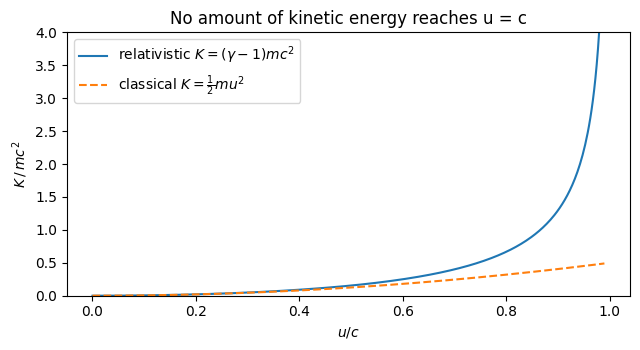

In [17]:
b = np.linspace(0, 0.99, 400)
plt.figure(figsize=(6.5, 3.6))
plt.plot(b, gam(b) - 1, label=r'relativistic $K = (\gamma - 1)mc^2$')
plt.plot(b, 0.5 * b**2, '--', label=r'classical $K = \frac{1}{2}mu^2$')
plt.ylim(0, 4); plt.xlabel(r'$u/c$'); plt.ylabel(r'$K\,/\,mc^2$')
plt.title('No amount of kinetic energy reaches u = c'); plt.legend()
plt.tight_layout(); plt.show()

**Worked numbers.** Energies of particles are quoted in electron
volts: $1\ \text{eV} = 1.602\times10^{-19}$ J.

In [18]:
e_charge = 1.602176634e-19              # C (so 1 eV = this many joules)
m_e = 9.1093837e-31                     # kg
mc2_e = m_e * C**2 / e_charge / 1e6     # electron rest energy, MeV
print(f"electron rest energy  m c^2 = {mc2_e:.4f} MeV")

def beta_from_K(K, mc2):
    g_ = 1 + K / mc2
    return np.sqrt(1 - 1 / g_**2)

# an electron accelerated through 1.00 MV
K = 1.00
print(f"electron with K = 1.00 MeV: gamma = {1 + K / mc2_e:.3f}, u = {beta_from_K(K, mc2_e):.4f} c")
print(f"   classical (1/2)mu^2 would give u = {np.sqrt(2 * K / mc2_e):.2f} c  -- faster than light, so wrong")

# rest energy of one gram of anything
print(f"\n1 gram of mass  ->  E = m c^2 = {1e-3 * C**2:.3e} J")

# deuterium + tritium -> helium-4 + neutron; masses in atomic mass units
u_MeV = 931.494
dm = (2.014102 + 3.016049) - (4.002602 + 1.008665)
print(f"\nD + T -> He-4 + n: mass decrease = {dm:.6f} u  ->  energy released = {dm * u_MeV:.2f} MeV")

# a photon needs at least two electron rest energies to create an electron-positron pair
print(f"pair-production threshold = 2 m c^2 = {2 * mc2_e:.3f} MeV")

assert np.isclose(mc2_e, 0.511, atol=5e-4)
assert np.isclose(beta_from_K(1.00, mc2_e), 0.9411, atol=5e-4)
assert np.isclose(dm * u_MeV, 17.59, atol=0.01)

electron rest energy  m c^2 = 0.5110 MeV
electron with K = 1.00 MeV: gamma = 2.957, u = 0.9411 c
   classical (1/2)mu^2 would give u = 1.98 c  -- faster than light, so wrong

1 gram of mass  ->  E = m c^2 = 8.988e+13 J

D + T -> He-4 + n: mass decrease = 0.018884 u  ->  energy released = 17.59 MeV
pair-production threshold = 2 m c^2 = 1.022 MeV


# Practice problems

Four short problems, one for each calculation-heavy objective. Try
them on paper first; the cell below prints and asserts the answers.

1. **(36.5)** A spaceship passes Earth at $0.8c$. The pilot's clock
   advances 30 min. How much time passes on Earth clocks?
2. **(36.6)** A metre stick moves along its length at $0.6c$. How long
   is it in the lab frame?
3. **(36.6)** A rocket moving at $0.8c$ fires a probe forward at $0.5c$
   relative to the rocket. How fast is the probe in the ground frame?
4. **(36.7, 36.8)** A proton ($mc^2 = 938.27$ MeV) has total energy
   three times its rest energy. Find its speed, kinetic energy and
   momentum (as $pc$).

In [19]:
# 1: the pilot's clock is present at both events, so 30 min is the proper time
a1 = gam(0.8) * 30
# 2: proper length 1 m, contracted by gamma
a2 = 1.0 / gam(0.6)
# 3: ground sees S' (rocket) moving at +0.8c, so invert the velocity rule: u = (u' + v)/(1 + u'v/c^2)
a3 = (0.5 + 0.8) / (1 + 0.5 * 0.8)
# 4: gamma = 3
mc2_p = 938.27
beta4 = np.sqrt(1 - 1 / 3**2)
K4 = (3 - 1) * mc2_p
pc4 = np.sqrt((3 * mc2_p)**2 - mc2_p**2)

print(f"1. Earth time = {a1:.0f} min")
print(f"2. length     = {a2:.2f} m")
print(f"3. probe speed = {a3:.4f} c")
print(f"4. u = {beta4:.4f} c,  K = {K4:.1f} MeV,  pc = {pc4:.1f} MeV")

assert np.isclose(a1, 50) and np.isclose(a2, 0.80) and np.isclose(a3, 0.9286, atol=1e-4)
assert np.isclose(beta4, 0.9428, atol=1e-4) and np.isclose(pc4, 3 * mc2_p * beta4)

1. Earth time = 50 min
2. length     = 0.80 m
3. probe speed = 0.9286 c
4. u = 0.9428 c,  K = 1876.5 MeV,  pc = 2653.8 MeV


# Summary sheet

| Quantity | Formula | When to use it |
|---|---|---|
| Lorentz factor | $\gamma = 1/\sqrt{1 - v^2/c^2}$ | always $\ge 1$ |
| Time dilation | $\Delta t = \gamma\,\Delta\tau$ | $\Delta\tau$ is measured by the one clock present at both events |
| Length contraction | $L = L_0/\gamma$ | $L_0$ is measured in the object's rest frame |
| Simultaneity | $\Delta t' = -\gamma v\,\Delta x/c^2$ | events simultaneous in S, separated by $\Delta x$ |
| Lorentz transformation | $x' = \gamma(x - vt)$, $t' = \gamma(t - vx/c^2)$ | any pair of events; the safe default |
| Velocity addition | $u' = \dfrac{u - v}{1 - uv/c^2}$ | never gives more than $c$ |
| Invariant interval | $(c\,\Delta t)^2 - (\Delta x)^2$ | same in every frame |
| Momentum | $p = \gamma m u$ | conserved in every frame |
| Energy | $E = \gamma mc^2$, $K = (\gamma - 1)mc^2$ | rest energy is $mc^2$ |
| Energy–momentum | $E^2 = (pc)^2 + (mc^2)^2$ | links $E$ and $p$ without needing $u$ |

**A habit that prevents most mistakes:** before using time dilation or
length contraction, name the two events and ask which frame has them at
the same place (proper time) or which frame has the object at rest
(proper length). If neither shortcut clearly applies, use the full
Lorentz transformation.

Related notebooks in this repository:
[`inertial_reference_frames.ipynb`](inertial_reference_frames.ipynb) and
[`magnetism_as_relativistic_electricity.ipynb`](magnetism_as_relativistic_electricity.ipynb).